# Neural network: predicting whether adolescents cross the BDI-II threshold

**Research question:** what factors can predict whether or not adolescents cross the clinical threshold for depression according to the BDI-II?

This notebook applies the Week 9 neural-network material (`00_week9_NeuralNetworks.ipynb`) to the project data. It uses the same target, features and train/test split as `logistic_regression.ipynb`, `knn.ipynb`, `decision_tree.ipynb` and `random_forest.ipynb`, so the results can be compared directly.

A **multilayer perceptron (MLP)** connects artificial neurons in layers:
1. **Input layer:** the seven features.
2. **Hidden layer:** neurons that each compute a weighted sum of the inputs and apply a non-linear activation.
3. **Output layer:** one neuron that gives the probability of being above the threshold.

**Learning goals (from Week 9), applied here**
- Calculate the output of a single neuron and connect it to logistic regression.
- Train an MLP and compare it with the logistic regression baseline.
- See how the network's settings (hidden layers, activation, `alpha`, early stopping) change the result.
- Compare decision boundaries of a linear model and a neural network.
- Evaluate the final model once on the held-out test set.

---
## Step 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
)

# Fixing the random seed makes the split, the folds and the network's starting weights reproducible
RANDOM_STATE = 42

---
## Step 2. Load data, define target and features

The target is `depressed` (1 if the BDI-II total is 14 or above, 0 if below). The seven features are the same as in the other model notebooks.

In [2]:
df = pd.read_csv("../data/processed/model_ready.csv")

feature_cols = [
    "screen_time_index", "est_leisure_screen_hours", "sex_binary",
    "sleep_quality_index", "avg_sleep_hours",
    "midsleep_weekend_hours", "social_jetlag_hours",
]
target = "depressed"   # 1 = BDI-II total >= 14, 0 = below

X = df[feature_cols]
y = df[target].astype(int)

print("X shape:", X.shape)
print(y.value_counts(normalize=True).rename({0: "not depressed", 1: "depressed"}).round(3))

X shape: (4810, 7)
depressed
not depressed    0.836
depressed        0.164
Name: proportion, dtype: float64


---
## Step 3. Train/test split

Same settings as the other model notebooks (20% test, seed 42), so the test set is the same 962 adolescents. It is not used until Step 10. All other evaluation uses cross-validation on the training set.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

baseline_acc = (y_test == 0).mean()
print("Training rows:", len(X_train), "| Test rows (kept aside):", len(X_test))
print(f"Depressed in training set: {y_train.mean():.1%}")
print(f"Training baseline (always 'not depressed'): {(y_train == 0).mean():.1%}")
print(f"Test baseline (always 'not depressed'): {baseline_acc:.1%}")

Training rows: 3848 | Test rows (kept aside): 962
Depressed in training set: 16.7%
Training baseline (always 'not depressed'): 83.3%
Test baseline (always 'not depressed'): 84.8%


## **Explanation**

- 3,848 adolescents train the models and 962 are kept back.
- About 16.7% of the training adolescents are above the threshold. A model that always predicts "not depressed" is already 83.3% accurate on the training set and 84.8% on the test set, so accuracy alone can look good while most real cases are missed. Precision, recall and F1 are reported throughout.

---
## Step 4. Logistic regression baseline, and one neuron by hand

The Week 9 notebook compares the neural network with logistic regression. Standardisation is placed inside a `Pipeline`, so the scaler is fitted on the training data only.

An artificial neuron performs two operations:
1. a **weighted sum** of its inputs plus a bias: $z = w_1x_1 + w_2x_2 + \cdots + b$
2. an **activation function** applied to that sum: $\hat{y} = \sigma(z)$, with $\sigma(z) = \dfrac{1}{1 + e^{-z}}$

With a sigmoid activation, a single neuron is the same model as logistic regression. The cell below checks this on one adolescent: it takes the weights and bias that logistic regression learned, computes $z$ and $\sigma(z)$ by hand, and compares the result with the model's own probability.

In [4]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])
logistic_model.fit(X_train, y_train)

weights = logistic_model.named_steps["model"].coef_[0]     # one weight per feature
bias = logistic_model.named_steps["model"].intercept_[0]

print("Learned weights (for standardised features):")
print(pd.Series(weights, index=feature_cols).round(3).to_string())
print(f"Bias: {bias:.3f}\n")

# One adolescent from the training set
person = X_train.iloc[[0]]
print("Example adolescent:")
print(person.iloc[0].to_string())
print("Actual class:", int(y_train.iloc[0]), "(0 = not depressed)\n")
x_scaled = logistic_model.named_steps["scaler"].transform(person)[0]

# Step 1: weighted sum
z = (weights * x_scaled).sum() + bias

# Step 2: sigmoid activation
sigmoid = lambda value: 1 / (1 + np.exp(-value))

print(f"Weighted sum z:              {z:.3f}")
print(f"Neuron output sigmoid(z):    {sigmoid(z):.3f}")
print(f"Logistic regression P(dep.): {logistic_model.predict_proba(person)[0, 1]:.3f}")

Learned weights (for standardised features):
screen_time_index           0.408
est_leisure_screen_hours   -0.314
sex_binary                  0.516
sleep_quality_index         0.592
avg_sleep_hours            -0.103
midsleep_weekend_hours      0.204
social_jetlag_hours        -0.024
Bias: -1.890

Example adolescent:
screen_time_index           3.667
est_leisure_screen_hours    5.500
sex_binary                  1.000
sleep_quality_index         1.250
avg_sleep_hours             9.150
midsleep_weekend_hours      5.230
social_jetlag_hours         2.330
Actual class: 0 (0 = not depressed)

Weighted sum z:              -2.018
Neuron output sigmoid(z):    0.117
Logistic regression P(dep.): 0.117


## **Explanation**

- **Weights:** the features are standardised, so the weights can be compared. The largest are sleep quality index (0.59), sex (0.52) and screen time index (0.41). A positive weight raises the weighted sum, and so raises the predicted probability of being above the threshold.
- **Bias (−1.89):** the baseline. For an adolescent who is average on every feature, the weighted sum is just the bias, and sigmoid(−1.89) ≈ 0.13.
- **Example adolescent:** a girl who sleeps 9.15 hours with a sleep quality index of 1.25 (few sleep problems). Her weighted sum is z = −2.018 and sigmoid(z) = 0.117.
- **The hand calculation matches the model exactly (0.117).** Logistic regression is one sigmoid neuron: a weighted sum plus a bias, passed through the sigmoid.
- With the 0.5 threshold, 0.117 gives "not depressed", which is correct for this adolescent.

---
## Step 5. Train a multilayer perceptron (MLP)

The settings are the ones used in the Week 9 notebook:
- `hidden_layer_sizes = (12,)`: one hidden layer with 12 neurons.
- `activation = "relu"`: each hidden neuron outputs $\max(0, z)$. Without a non-linear activation, stacked layers would still be one linear model.
- `alpha = 0.0001`: weight decay (L2), the same idea as Ridge.
- `learning_rate_init = 0.01`: the starting step size for the weight updates.
- `max_iter = 2000`: the maximum number of epochs (full passes through the training data).

During `.fit()` the estimator runs the forward pass, computes the loss, backpropagates the error and updates the weights, repeating until the loss stops improving.

Layer sizes (input, hidden, output): [7, 12, 1]
Number of learned parameters (weights + biases): 109
Epochs run: 113
Training accuracy, MLP:                 0.843
Training accuracy, logistic regression: 0.839


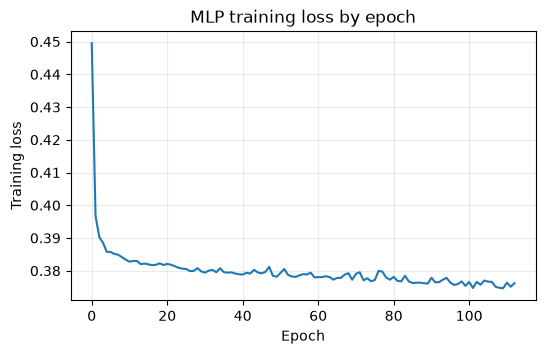

In [5]:
neural_network = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(12,),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.01,
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])
neural_network.fit(X_train, y_train)

mlp = neural_network.named_steps["model"]
n_parameters = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)

print("Layer sizes (input, hidden, output):", [X_train.shape[1], *mlp.hidden_layer_sizes, mlp.n_outputs_])
print("Number of learned parameters (weights + biases):", n_parameters)
print("Epochs run:", mlp.n_iter_)
print(f"Training accuracy, MLP:                 {neural_network.score(X_train, y_train):.3f}")
print(f"Training accuracy, logistic regression: {logistic_model.score(X_train, y_train):.3f}")

plt.figure(figsize=(6, 3.5))
plt.plot(mlp.loss_curve_)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("MLP training loss by epoch")
plt.grid(alpha=0.25)
plt.show()

## **Explanation**

- **Structure:** 7 inputs, 12 hidden neurons and 1 output neuron.
- **109 parameters** are learned (7 × 12 weights + 12 biases into the hidden layer, then 12 weights + 1 bias into the output). Logistic regression learned 8.
- **Training stopped after 113 epochs**, well short of the 2,000 allowed, because the loss had stopped improving.
- **Loss curve:** the loss drops sharply in the first few epochs (from about 0.45 to 0.39) and then flattens at about 0.376. Most of what the network learns, it learns early.
- **Training accuracy is 0.843**, against 0.839 for logistic regression and a baseline of 0.833. With thirteen times as many parameters, the network fits the training data only slightly better. This is very different from the random forest, which reached 1.000 on the training data.

---
## Step 6. Evaluate with cross-validation

Training accuracy is not a fair measure. Both models are evaluated with the same **5-fold cross-validation** on the training set as in `random_forest.ipynb`. Because each model is a pipeline, the scaler is refitted inside every training fold, so the held-out fold never influences the preprocessing.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # same class mix in every fold
metrics = ["accuracy", "precision", "recall", "f1"]

def cv_row(model):
    # Mean and SD of each metric across the five folds, plus mean training accuracy
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics, return_train_score=True)
    row = {"Train accuracy": s["train_accuracy"].mean()}
    for m in metrics:
        row[m.capitalize()] = s[f"test_{m}"].mean()
        row[f"{m.capitalize()} SD"] = s[f"test_{m}"].std()
    return row

cv_results = pd.DataFrame({
    "Logistic regression": cv_row(logistic_model),
    "MLP (12 neurons)": cv_row(neural_network),
}).T

print(f"Baseline accuracy in the training set (always 'not depressed'): {(y_train == 0).mean():.3f}")
cv_results.round(3)

Baseline accuracy in the training set (always 'not depressed'): 0.833


,Train accuracy,Accuracy,Accuracy SD,Precision,Precision SD,Recall,Recall SD,F1,F1 SD
Logistic regression,0.841,0.836,0.012,0.545,0.138,0.136,0.024,0.217,0.042
MLP (12 neurons),0.845,0.838,0.010,0.552,0.114,0.156,0.045,0.240,0.059


## **Explanation**

- **Accuracy:** 0.838 for the MLP and 0.836 for logistic regression, both about level with the baseline of 0.833.
- **Recall:** the MLP finds 15.6% of the adolescents above the threshold, logistic regression 13.6%. Both miss most real cases.
- **F1:** 0.240 (SD 0.059) for the MLP against 0.217 (SD 0.042) for logistic regression. The difference of 0.023 is smaller than the variation between folds, so it is not evidence that the network is better.
- **Little overfitting:** the MLP's training accuracy within the folds (0.845) is close to its cross-validated accuracy (0.838).
- The non-linear model performs about the same as the linear one. This suggests there is little non-linear pattern in these seven features for the hidden layer to find.

---
## Step 7. Changing the network's settings

The Week 9 notebook recommends three exercises: change the hidden layer sizes, change the activation to `tanh`, and increase `alpha` from 0.0001 to 0.1. One setting is changed at a time, with the split and seed fixed.

The Week 9 notebook compares test scores. Here the settings are compared with cross-validation on the training set instead, as taught in Week 8, so the test set is still unused.

In [7]:
def make_mlp(hidden=(12,), activation="relu", alpha=0.0001):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=hidden, activation=activation, solver="adam",
            alpha=alpha, learning_rate_init=0.01, max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ])

settings = {
    "(12,) relu, alpha 0.0001  [main model]": make_mlp(),
    "(4,)": make_mlp(hidden=(4,)),
    "(30,)": make_mlp(hidden=(30,)),
    "(30, 15)": make_mlp(hidden=(30, 15)),
    "(12,) tanh": make_mlp(activation="tanh"),
    "(12,) alpha 0.1": make_mlp(alpha=0.1),
}

settings_results = pd.DataFrame({name: cv_row(model) for name, model in settings.items()}).T
settings_results.round(3)

,Train accuracy,Accuracy,Accuracy SD,Precision,Precision SD,Recall,Recall SD,F1,F1 SD
"(12,) relu, alpha 0.0001 [main model]",0.845,0.838,0.010,0.552,0.114,0.156,0.045,0.240,0.059
"(4,)",0.842,0.840,0.009,0.597,0.117,0.137,0.025,0.223,0.040
"(30,)",0.849,0.839,0.009,0.525,0.084,0.207,0.110,0.286,0.113
"(30, 15)",0.881,0.814,0.003,0.398,0.025,0.237,0.040,0.296,0.037
"(12,) tanh",0.849,0.830,0.010,0.472,0.087,0.173,0.033,0.252,0.045
"(12,) alpha 0.1",0.847,0.839,0.012,0.579,0.142,0.158,0.020,0.247,0.037


## **Explanation**

- **Fewer neurons, (4,):** F1 0.223, about the same as logistic regression (0.217).
- **More neurons, (30,):** F1 rises to 0.286, but the SD is 0.113 and recall varies widely between folds (SD 0.110). The result is unstable.
- **Two hidden layers, (30, 15):** the highest training accuracy (0.881) but the lowest cross-validated accuracy (0.814), which is below the baseline of 0.833. The gap between the two is the widest in the table: the larger network is starting to **overfit**. Its recall is higher (0.237) because it flags more adolescents, and its precision falls to 0.398.
- **tanh instead of ReLU:** similar (F1 0.252, accuracy 0.830).
- **Stronger weight decay, alpha = 0.1:** about the same as the main model (F1 0.247 against 0.240), with steadier recall across folds (SD 0.020 against 0.045). There was little overfitting to remove at this network size.
- **No setting clearly beats the others.** Accuracy stays between 0.81 and 0.84, around the baseline, and the F1 differences are mostly within one SD. The Week 9 settings are kept as the main model; picking the top row of a table of noisy scores would be reading noise.

---
## Step 8. Early stopping

With `early_stopping=True`, scikit-learn holds back 10% of the training data as a **validation set** and stops training when the validation score stops improving.

In [8]:
mlp_es = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(12,), learning_rate_init=0.01, max_iter=2000,
        early_stopping=True, validation_fraction=0.1, random_state=RANDOM_STATE
    ))
])
mlp_es.fit(X_train, y_train)
m = mlp_es.named_steps["model"]

print(f"Epochs with early stopping: {m.n_iter_}  (without: {mlp.n_iter_})")
print(f"Validation set size: {int(np.ceil(0.1 * len(X_train)))} adolescents")
print(f"Best validation accuracy: {m.best_validation_score_:.3f}")

es_cv = pd.DataFrame({
    "MLP (12 neurons)": cv_row(neural_network),
    "MLP with early stopping": cv_row(mlp_es),
}).T
es_cv.round(3)

Epochs with early stopping: 34  (without: 113)
Validation set size: 385 adolescents
Best validation accuracy: 0.849


,Train accuracy,Accuracy,Accuracy SD,Precision,Precision SD,Recall,Recall SD,F1,F1 SD
MLP (12 neurons),0.845,0.838,0.010,0.552,0.114,0.156,0.045,0.240,0.059
MLP with early stopping,0.839,0.834,0.008,0.557,0.145,0.094,0.027,0.156,0.041


## **Explanation**

- **Training stops after 34 epochs** instead of 113.
- **The validation set is 385 adolescents**, far more than the 45 in the Week 9 example, so the stopping decision is more reliable. Only about 64 of them are above the threshold, however.
- **Cross-validated recall falls from 0.156 to 0.094 and F1 from 0.240 to 0.156.** Accuracy is unchanged (0.834 against 0.838).
- Early stopping monitors validation *accuracy*. With imbalanced classes, accuracy is high for a network that mostly predicts "not depressed", so stopping early leaves a more cautious network.
- Early stopping is a tool against overfitting. The main network was not overfitting (Step 6), so it gave no benefit here.

---
## Step 9. Decision boundaries with two features

The Week 9 notebook plots decision boundaries for a two-feature dataset. A boundary for seven features cannot be drawn, so for this plot only, both models are refitted on two features: average sleep hours and the sleep quality index. The shaded regions show which class each model predicts.

These two-feature models are for illustration. The seven-feature models above are the ones evaluated.

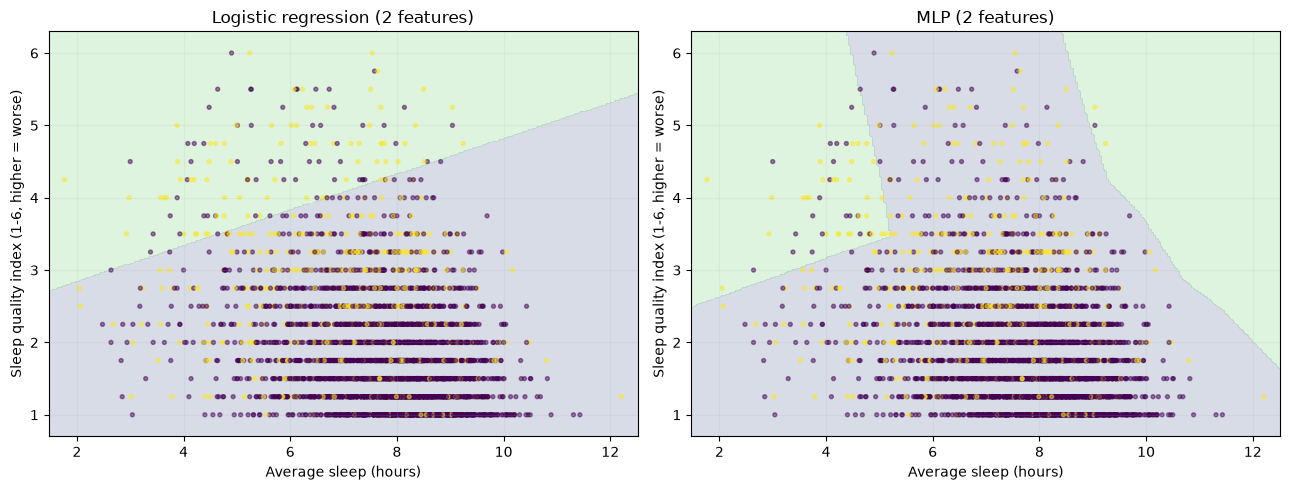

Training adolescents predicted 'depressed': logistic regression 127, MLP 54 (actual: 641)


In [9]:
two_features = ["avg_sleep_hours", "sleep_quality_index"]
X2_train = X_train[two_features].to_numpy()

logistic_2d = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression())]).fit(X2_train, y_train)
mlp_2d = make_mlp().fit(X2_train, y_train)

def plot_decision_boundary(model, X_data, y_data, title, ax):
    # Predict the class for every point on a grid and shade the regions
    x_min, x_max = X_data[:, 0].min() - 0.3, X_data[:, 0].max() + 0.3
    y_min, y_max = X_data[:, 1].min() - 0.3, X_data[:, 1].max() + 0.3
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    predicted = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, predicted, alpha=0.2, levels=[-0.5, 0.5, 1.5])
    ax.scatter(X_data[:, 0], X_data[:, 1], c=y_data, s=8, alpha=0.5)
    ax.set_xlabel("Average sleep (hours)")
    ax.set_ylabel("Sleep quality index (1-6, higher = worse)")
    ax.set_title(title)
    ax.grid(alpha=0.15)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_decision_boundary(logistic_2d, X2_train, y_train, "Logistic regression (2 features)", axes[0])
plot_decision_boundary(mlp_2d, X2_train, y_train, "MLP (2 features)", axes[1])
plt.tight_layout()
plt.show()

print("Training adolescents predicted 'depressed':",
      f"logistic regression {int(logistic_2d.predict(X2_train).sum())},",
      f"MLP {int(mlp_2d.predict(X2_train).sum())}",
      f"(actual: {int(y_train.sum())})")

## **Explanation**

- **Logistic regression** draws one straight line. It predicts "depressed" only in the upper-left region: short sleep combined with a high sleep quality index (more sleep problems).
- **The MLP's boundary bends.** It predicts "depressed" in two regions: on the left (less than about 5 hours of sleep with an index above about 3) and on the far right (very long sleep, roughly 9 to 10 hours or more). This resembles the lecture's example that both too little and too much sleep can be associated with worse outcomes. Very few adolescents lie in the right-hand region, so that part of the boundary rests on little data.
- **The two classes overlap heavily.** Adolescents above the threshold (yellow) are spread throughout the same area as those below it (purple). No boundary, straight or curved, separates them well.
- With these two features, logistic regression flags 127 training adolescents and the MLP 54, out of 641 who are actually above the threshold.
- In the Week 9 two-moons data, a curved boundary solved the problem. Here a more flexible boundary does not help, because the limit is the overlap between the groups and not the shape of the boundary.

---
## Step 10. Final evaluation on the test set

The test set is now used, once. Both models were already trained on the full training set (Steps 4 and 5). The main MLP (12 neurons, the Week 9 settings) is the one evaluated; it was not re-chosen from Step 7.

Test baseline (always 'not depressed'): 0.848
Real cases in the test set: 146


,Accuracy,Precision,Recall,F1,Flagged as depressed,Real cases caught
Logistic regression,0.849,0.511,0.158,0.241,45.0,23.0
MLP (12 neurons),0.836,0.421,0.219,0.288,76.0,32.0


Classification report, MLP:


               precision    recall  f1-score   support

not depressed       0.87      0.95      0.91       816
    depressed       0.42      0.22      0.29       146

     accuracy                           0.84       962
    macro avg       0.65      0.58      0.60       962
 weighted avg       0.80      0.84      0.81       962



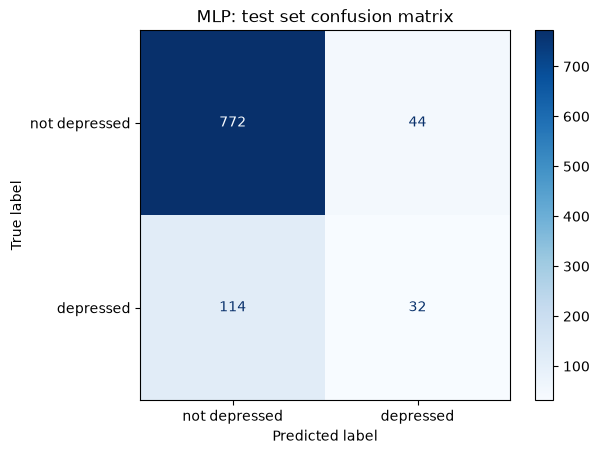

In [10]:
def test_row(model):
    pred = model.predict(X_test)
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Flagged as depressed": int(pred.sum()),
        "Real cases caught": int(((pred == 1) & (y_test == 1)).sum()),
    }

test_pred = neural_network.predict(X_test)

print(f"Test baseline (always 'not depressed'): {baseline_acc:.3f}")
print(f"Real cases in the test set: {int(y_test.sum())}")
display(pd.DataFrame({
    "Logistic regression": test_row(logistic_model),
    "MLP (12 neurons)": test_row(neural_network),
}).T.round(3))

print("Classification report, MLP:")
print(classification_report(y_test, test_pred, target_names=["not depressed", "depressed"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["not depressed", "depressed"], cmap="Blues"
)
plt.title("MLP: test set confusion matrix")
plt.show()

## **Explanation**

- **Confusion matrix (MLP):** 772 true negatives, 44 false positives, 114 false negatives, 32 true positives.
- **Accuracy 0.836**, below the baseline of 0.848. Logistic regression reaches 0.849.
- **Precision 0.42:** 32 of the 76 adolescents flagged are above the threshold.
- **Recall 0.22:** 32 of the 146 real cases are caught, against 23 for logistic regression (0.16). 114 are missed.
- **F1 0.288** against 0.241 for logistic regression.
- **The trade-off:** the MLP catches 9 more real cases than logistic regression at the cost of 22 more false alarms. It flags more adolescents; it is not clearly more accurate.
- **Compared with the random forest** (25 of 146 caught, accuracy 0.835), the MLP is in the same range. The test results agree with the cross-validation: the differences between the models are small.

---
## Step 11. Save results for the comparison notebook

The MLP's test-set predictions are saved in the same format as the other model notebooks, so they can be added to `model_comparison.ipynb`.

In [11]:
import os
os.makedirs("../results", exist_ok=True)

pd.DataFrame({
    "actual": y_test.values,
    "predicted": test_pred,
    "prob_depressed": neural_network.predict_proba(X_test)[:, 1].round(3),
}, index=y_test.index).to_csv("../results/mlp_predictions.csv", index_label="row")

print("Saved ../results/mlp_predictions.csv")

Saved ../results/mlp_predictions.csv


---
## Summary of findings

- **A single sigmoid neuron is logistic regression:** the hand calculation of the weighted sum and sigmoid reproduced the model's probability exactly.
- An **MLP** with one hidden layer of 12 ReLU neurons learns 109 parameters and can draw non-linear boundaries. Training stopped after 113 epochs.
- **The network is not a clearly better classifier for this question.** In cross-validation its F1 is 0.240 against 0.217 for logistic regression, a difference smaller than the variation between folds. On the test set it catches 32 of 146 real cases (recall 0.22) with accuracy below the baseline.
- **Making the network larger led to overfitting:** two hidden layers raised training accuracy to 0.881 while cross-validated accuracy fell below the baseline.
- **Weight decay and early stopping did not help**, because the main network was not overfitting.
- **The decision-boundary plot shows why:** adolescents above and below the threshold overlap heavily on these features, so a more flexible boundary has little to gain. This matches the earlier notebooks, where KNN, the decision tree and the random forest also caught only a small share of real cases.
- A neural network is **harder to interpret** than logistic regression: 109 weights cannot be read the way seven coefficients can.
- This fits the lecture's point that on typical tabular data, simpler models often perform as well as neural networks. A neural network is one modelling option, not automatically the best one.